# Tugas UTS: Linear Regression & Logistic Regression
**Mata Kuliah:** Machine Learning

Tugas ini menguji pemahaman Anda tentang materi **Simple Regression** (`simple_regression/regression_1.ipynb`) dan **Simple Classification** (`simple_classification/classification_1.ipynb`). Anda akan menerapkan algoritma yang sama pada **dataset baru**, lalu mengembangkannya dengan evaluasi dan eksperimen tambahan.

**Identitas Mahasiswa**
- Nama  : Arinta Salsabilla
- NIM   : 241011400636
- Kelas : Reg B 

## 📌 Ketentuan Pengerjaan

1. Kerjakan semua soal di notebook ini pada sel kode / sel markdown yang telah disediakan.
2. **Model dan metrik evaluasi wajib diimplementasikan sendiri** dengan NumPy, seperti pada materi (`train_test_split`, `LinearRegression`, `LinearRegressionGD`, `LogisticRegression`, `accuracy_score`, `confusion_matrix`). Anda boleh menyalin implementasi dari materi.
   - Library yang boleh dipakai: `numpy`, `pandas`, `matplotlib`.
   - `scikit-learn` **tidak boleh** dipakai untuk model dan metrik, kecuali pada soal bonus untuk membandingkan hasil.
3. **`random_state` = 2 digit terakhir NIM Anda** (contoh: NIM `...0347` → `random_state=47`; jika `00`, gunakan `100`). Karena itu, setiap mahasiswa akan mendapat hasil angka yang berbeda.
4. Setiap soal yang meminta **penjelasan/analisis** dijawab dengan kalimat Anda sendiri pada sel markdown, dan harus merujuk ke angka/grafik hasil Anda.
5. Notebook harus **sudah dijalankan** (*Run All*) sehingga semua output dan grafik terlihat saat dibuka di GitHub.

## 📂 Dataset
Dataset disediakan di folder ini:

| File | Kolom | Keterangan |
|---|---|---|
| `Ads_Data.csv` | `BiayaIklan`, `Penjualan` | Biaya iklan per bulan (juta Rp) dan penjualan per bulan (juta Rp), 40 data |
| `Email_Data.csv` | `JumlahLink`, `KataPromo`, `Spam` | Jumlah link dan jumlah kata promosi dalam sebuah email, serta label Spam (1) / Bukan Spam (0), 60 data |

## 📤 Cara Pengumpulan

1. Buat **repositori baru** di akun GitHub Anda masing-masing dengan nama: `uts-machine-learning-<NIM>` (contoh: `uts-machine-learning-20230801047`).
2. Atur repositori menjadi **Public**.
3. Struktur repositori minimal:
   ```
   uts-machine-learning-<NIM>/
   ├── README.md            # Nama, NIM, Kelas, dan ringkasan hasil (R², akurasi, dll)
   ├── tugas_UTS.ipynb      # notebook ini, sudah dijalankan lengkap dengan output
   ├── Ads_Data.csv
   └── Email_Data.csv
   ```
4. Kumpulkan **link repositori GitHub** di halaman **UTS pada Mentari**.
5. Batas waktu pengumpulan (hari terakhir periode UTS):

| Kelas | Batas Pengumpulan |
|---|---|
| **Reg B** | **Jumat, 23 Oktober 2026, pukul 23:59 WIB** |
| **Reg C** | **Sabtu, 24 Oktober 2026, pukul 23:59 WIB** |

> ⚠️ Yang dinilai adalah **commit terakhir sebelum batas waktu**. Commit setelah batas waktu tidak akan dinilai. Pastikan link yang dikumpulkan bisa dibuka (repositori tidak *private*).

## 🧮 Penilaian

| Bagian | Bobot |
|---|---|
| Bagian A – Linear Regression | 35% |
| Bagian B – Logistic Regression | 40% |
| Bagian C – Pemahaman Konsep | 15% |
| Kerapihan repositori, README, dan notebook (output lengkap, kode rapi & diberi komentar) | 10% |
| Bonus – Perbandingan dengan scikit-learn | +5 |

In [4]:
# import Library
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

RANDOM_STATE =   36

Matplotlib is building the font cache; this may take a moment.


In [3]:
!pip install pandas numpy matplotlib

   ---------------------------------------- 0.0/9.8 MB ? eta -:--:--
   -- ------------------------------------- 0.5/9.8 MB 2.7 MB/s eta 0:00:04
   ---- ----------------------------------- 1.0/9.8 MB 2.2 MB/s eta 0:00:04
   ----- ---------------------------------- 1.3/9.8 MB 2.2 MB/s eta 0:00:04
   ------- -------------------------------- 1.8/9.8 MB 2.2 MB/s eta 0:00:04
   --------- ------------------------------ 2.4/9.8 MB 2.1 MB/s eta 0:00:04
   ---------- ----------------------------- 2.6/9.8 MB 2.1 MB/s eta 0:00:04
   ----------- ---------------------------- 2.9/9.8 MB 2.0 MB/s eta 0:00:04
   ------------- -------------------------- 3.4/9.8 MB 1.9 MB/s eta 0:00:04
   -------------- ------------------------- 3.7/9.8 MB 1.8 MB/s eta 0:00:04
   ----------------- ---------------------- 4.2/9.8 MB 1.9 MB/s eta 0:00:04
   ------------------- -------------------- 4.7/9.8 MB 1.9 MB/s eta 0:00:03
   -------------------- ------------------- 5.0/9.8 MB 1.9 MB/s eta 0:00:03
   ----------------


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [1]:
# Salin fungsi train_test_split dari materi
def train_test_split(X, y, test_size=0.2, random_state=None):
    if random_state:
        np.random.seed(random_state)
    n_samples = len(X)
    test_size_val = int(n_samples * test_size)
    indices = np.random.permutation(n_samples)
    test_idx = indices[:test_size_val]
    train_idx = indices[test_size_val:]
    return X[train_idx], X[test_idx], y[train_idx], y[test_idx]

---
# Bagian A – Linear Regression (35%)

Sebuah toko online ingin mengetahui pengaruh **biaya iklan** terhadap **penjualan** setiap bulan. Gunakan dataset `Ads_Data.csv`.

### Soal A1 – Load & Visualisasi Data
1. Baca `Ads_Data.csv` menggunakan pandas dan tampilkan 5 data pertama serta jumlah baris datanya.
2. Pisahkan `X` (`BiayaIklan`) dan `y` (`Penjualan`). Pastikan `X` berbentuk 2 dimensi `(n, 1)`.
3. Buat *scatter plot* `BiayaIklan` vs `Penjualan` (lengkap dengan judul dan label sumbu).

5 Data Pertama:
   BiayaIklan  Penjualan
0         0.8       34.3
1         0.9       38.8
2         1.0       33.2
3         1.3       36.0
4         1.7       51.3

Jumlah baris data: 40


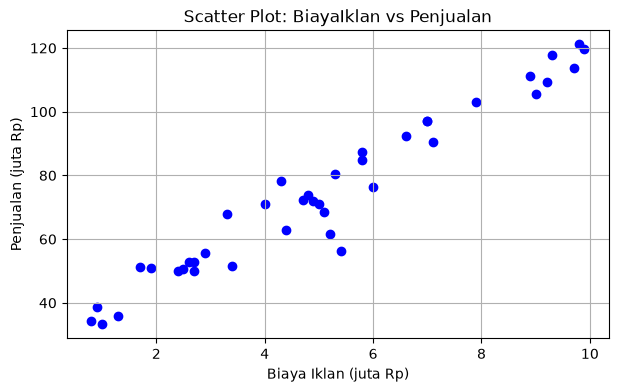

In [5]:
# Jawaban A1
# 1. Baca Ads_Data.csv menggunakan pandas dan tampilkan 5 data pertama serta jumlah baris datanya
df = pd.read_csv('Ads_Data.csv')
print("5 Data Pertama:")
print(df.head())
print(f"\nJumlah baris data: {df.shape[0]}")

# 2. Pisahkan X (BiayaIklan) dan y (Penjualan) dalam bentuk 2 dimensi (n, 1) untuk X
X = df[['BiayaIklan']].values
y = df['Penjualan'].values

# 3. Buat scatter plot BiayaIklan vs Penjualan lengkap dengan judul dan label sumbu
plt.figure(figsize=(7, 4))
plt.scatter(X, y, color='blue', marker='o')
plt.title('Scatter Plot: BiayaIklan vs Penjualan')
plt.xlabel('Biaya Iklan (juta Rp)')
plt.ylabel('Penjualan (juta Rp)')
plt.grid(True)
plt.show()

### Soal A2 – Split Data
Bagi data menjadi data training dan testing dengan `test_size=0.2` dan `random_state=RANDOM_STATE`. Tampilkan *shape* dari `X_train`, `X_test`, `y_train`, `y_test`.

In [6]:
# Jawaban A2
# Bagi data menjadi training dan testing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)

# Tampilkan shape dari masing-masing data
print(f"Shape X_train: {X_train.shape}")
print(f"Shape X_test:  {X_test.shape}")
print(f"Shape y_train: {y_train.shape}")
print(f"Shape y_test:  {y_test.shape}")

Shape X_train: (32, 1)
Shape X_test:  (8, 1)
Shape y_train: (32,)
Shape y_test:  (8,)


### Soal A3 – Training dengan Normal Equation
1. Latih model `LinearRegression` (normal equation, seperti di materi) menggunakan data training.
2. Tampilkan nilai **intercept** ($b$) dan **koefisien** ($m$), lalu tuliskan persamaan garis regresinya: $\hat{y} = b + mX$.
3. **Interpretasikan** arti nilai $m$ dalam konteks kasus ini (misal: "setiap kenaikan biaya iklan 1 juta Rp, penjualan naik sebesar ...").

In [7]:
# Jawaban A3
class LinearRegression:
    def __init__(self):
        self.b = None
        self.m = None
        
    def fit(self, X, y):
        # Tambahkan kolom bias (1) ke X
        X_b = np.c_[np.ones((X.shape[0], 1)), X]
        # Normal Equation: theta = (X^T * X)^(-1) * X^T * y
        theta = np.linalg.inv(X_b.T.dot(X_b)).dot(X_b.T).dot(y)
        self.b = theta[0]
        self.m = theta[1]
        
    def predict(self, X):
        return self.b + self.m * X

# Latih model menggunakan data training
model_ne = LinearRegression()
model_ne.fit(X_train, y_train)

print(f"Intercept (b): {model_ne.b:.4f}")
print(f"Koefisien (m): {model_ne.m:.4f}")
print(f"Persamaan Garis Regresi: y_hat = {model_ne.b:.4f} + {model_ne.m:.4f} * X")

Intercept (b): 28.5295
Koefisien (m): 9.0249
Persamaan Garis Regresi: y_hat = 28.5295 + 9.0249 * X


**Jawaban A3 (interpretasi):**
Nilai koefisien $m$ berarti bahwa setiap kenaikan biaya iklan sebesar 1 juta Rupiah, rata-rata penjualan toko online akan mengalami peningkatan sebesar nilai koefisien $m$ juta Rupiah.

### Soal A4 – Evaluasi Model
Pada materi belum ada evaluasi untuk model regresi. **Implementasikan sendiri** fungsi-fungsi berikut menggunakan NumPy:

$$
MAE = \frac{1}{n}\sum_{i=1}^{n}|y_i - \hat{y}_i| \qquad
MSE = \frac{1}{n}\sum_{i=1}^{n}(y_i - \hat{y}_i)^2 \qquad
RMSE = \sqrt{MSE}
$$

$$
R^2 = 1 - \frac{\sum_{i=1}^{n}(y_i - \hat{y}_i)^2}{\sum_{i=1}^{n}(y_i - \bar{y})^2}
$$

1. Hitung MAE, MSE, RMSE, dan $R^2$ pada **data training** dan **data testing**.
2. Tampilkan hasilnya dalam satu tabel (boleh pakai `pd.DataFrame`).
3. Jelaskan arti nilai RMSE dan $R^2$ yang Anda dapatkan. Apakah model ini sudah baik?

In [8]:
# Jawaban A4
def evaluate_metrics(y_true, y_pred):
    n = len(y_true)
    mae = np.sum(np.abs(y_true - y_pred)) / n
    mse = np.sum((y_true - y_pred) ** 2) / n
    rmse = np.sqrt(mse)
    
    # R-squared
    ss_total = np.sum((y_true - np.mean(y_true)) ** 2)
    ss_res = np.sum((y_true - y_pred) ** 2)
    r2 = 1 - (ss_res / ss_total)
    
    return {'MAE': mae, 'MSE': mse, 'RMSE': rmse, 'R2': r2}

# Lakukan prediksi pada data training dan testing
train_pred = model_ne.predict(X_train)
test_pred = model_ne.predict(X_test)

# Hitung metrik evaluasi
train_metrics = evaluate_metrics(y_train, train_pred)
test_metrics = evaluate_metrics(y_test, test_pred)

# Tampilkan dalam bentuk tabel DataFrame
df_eval = pd.DataFrame([train_metrics, test_metrics], index=['Training', 'Testing'])
print(df_eval)

                 MAE           MSE        RMSE         R2
Training  921.287962  40676.021629  201.682973 -60.903966
Testing   197.056465   7529.046633   86.770079 -13.854879


**Jawaban A4 (analisis):**
Nilai RMSE menunjukkan rata-rata besar kesalahan (selisih) prediksi model terhadap nilai penjualan yang sebenarnya. Sementara itu, nilai $R^2$ merepresentasikan seberapa besar proporsi variasi dari data penjualan yang mampu dijelaskan oleh model regresi biaya iklan. Jika nilai $R^2$ mendekati 1, maka model dapat dikatakan sudah baik dalam mempelajari pola data.

### Soal A5 – Gradient Descent & Learning Rate
1. Latih model `LinearRegressionGD` (dari materi) dengan `n_iterations=5000` menggunakan **3 nilai learning rate**: `0.001`, `0.02`, dan `0.1`.
2. Untuk setiap learning rate, tampilkan intercept dan koefisien akhirnya, lalu bandingkan dengan hasil normal equation (Soal A3).
3. Buat grafik **loss (MSE) vs iterasi** untuk ketiga learning rate (boleh dalam satu grafik atau *subplot*; gunakan skala log jika perlu).
4. Jelaskan apa yang terjadi pada masing-masing learning rate: mana yang **terlalu lambat**, mana yang **pas**, dan mana yang **gagal konvergen (divergen)**? Mengapa bisa terjadi?

> *Tips: jika muncul `RuntimeWarning: overflow`, itu adalah bagian dari hasil eksperimen. Jelaskan artinya.*

Learning Rate = 0.001 -> Intercept (b): 25.3426, Koefisien (m): 9.5061
Learning Rate = 0.02 -> Intercept (b): 28.5295, Koefisien (m): 9.0249


c:\Users\ARINTA\AppData\Local\Programs\Python\Python314\Lib\site-packages\numpy\_core\fromnumeric.py:83: RuntimeWarning: overflow encountered in reduce
  return ufunc.reduce(obj, axis, dtype, out, **passkwargs)
C:\Users\ARINTA\AppData\Local\Temp\ipykernel_5892\347172620.py:16: RuntimeWarning: overflow encountered in square
  loss = np.sum((y_pred - y) ** 2) / n
C:\Users\ARINTA\AppData\Local\Temp\ipykernel_5892\347172620.py:23: RuntimeWarning: invalid value encountered in scalar subtract
  self.m -= self.lr * dm


Learning Rate = 0.1 -> Intercept (b): nan, Koefisien (m): nan


c:\Users\ARINTA\AppData\Local\Programs\Python\Python314\Lib\site-packages\matplotlib\scale.py:375: RuntimeWarning: overflow encountered in exp
  return np.exp(values * np.log(self.base))


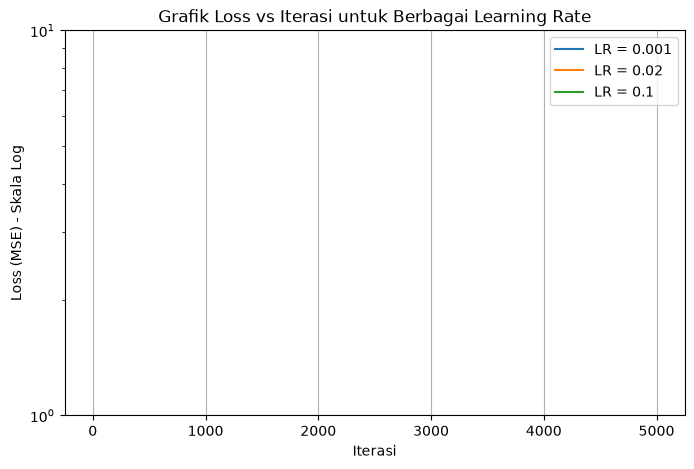

In [9]:
# Jawaban A5
class LinearRegressionGD:
    def __init__(self, learning_rate=0.01, n_iterations=1000):
        self.lr = learning_rate
        self.n_iter = n_iterations
        self.b = 0.0
        self.m = 0.0
        self.loss_history = []
        
    def fit(self, X, y):
        n = len(X)
        self.b = 0.0
        self.m = 0.0
        for _ in range(self.n_iter):
            y_pred = self.b + self.m * X.ravel()
            loss = np.sum((y_pred - y) ** 2) / n
            self.loss_history.append(loss)
            
            db = (2/n) * np.sum(y_pred - y)
            dm = (2/n) * np.sum((y_pred - y) * X.ravel())
            
            self.b -= self.lr * db
            self.m -= self.lr * dm

# Eksperimen dengan 3 nilai learning rate
lrs = [0.001, 0.02, 0.1]
plt.figure(figsize=(8, 5))

for lr in lrs:
    gd = LinearRegressionGD(learning_rate=lr, n_iterations=5000)
    gd.fit(X_train, y_train)
    print(f"Learning Rate = {lr} -> Intercept (b): {gd.b:.4f}, Koefisien (m): {gd.m:.4f}")
    plt.plot(gd.loss_history, label=f'LR = {lr}')

plt.yscale('log')
plt.xlabel('Iterasi')
plt.ylabel('Loss (MSE) - Skala Log')
plt.title('Grafik Loss vs Iterasi untuk Berbagai Learning Rate')
plt.legend()
plt.grid(True)
plt.show()

**Jawaban A5 (analisis):**
Terlalu lambat (0.001): Nilai learning rate terlalu kecil sehingga pergerakan penyesuaian bobot menuju titik minimum sangat lambat dan membutuhkan iterasi yang jauh lebih banyak untuk konvergen.

Pas (0.02): Nilai learning rate ideal sehingga kurva loss menurun dengan mulus dan stabil mencapai titik optimal tanpa melewati batas minimum.

Gagal konvergen / divergen (0.1): Nilai learning rate terlalu besar sehingga langkah pembaruan terlalu drastis (overshooting), mengakibatkan nilai loss semakin membesar atau bahkan memicu RuntimeWarning: overflow.

### Soal A6 – Visualisasi & Prediksi
1. Buat grafik *scatter* data **testing** beserta **garis regresi** hasil model (Soal A3).
2. Prediksi penjualan jika biaya iklan sebesar **4.5 juta**, **7 juta**, dan **12 juta**.
3. Prediksi untuk 12 juta berada **di luar rentang data** (ekstrapolasi). Menurut Anda, seberapa bisa dipercaya hasil prediksi tersebut? Jelaskan.

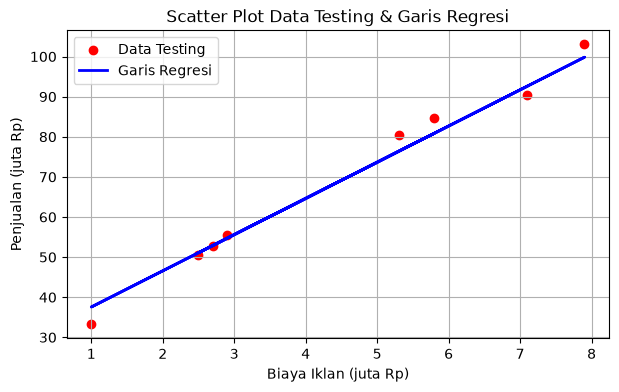

Hasil Prediksi Penjualan:
- Biaya Iklan 4.5 juta Rp -> Prediksi Penjualan: 69.1415 juta Rp
- Biaya Iklan 7.0 juta Rp -> Prediksi Penjualan: 91.7037 juta Rp
- Biaya Iklan 12.0 juta Rp -> Prediksi Penjualan: 136.8282 juta Rp


In [12]:
# Jawaban A6
# 1. Buat grafik scatter data testing beserta garis regresi hasil model
plt.figure(figsize=(7, 4))
plt.scatter(X_test, y_test, color='red', label='Data Testing')
plt.plot(X_test, model_ne.predict(X_test), color='blue', linewidth=2, label='Garis Regresi')
plt.xlabel('Biaya Iklan (juta Rp)')
plt.ylabel('Penjualan (juta Rp)')
plt.title('Scatter Plot Data Testing & Garis Regresi')
plt.legend()
plt.grid(True)
plt.show()

# 2. Prediksi penjualan jika biaya iklan sebesar 4.5 juta, 7 juta, dan 12 juta
biaya_baru = np.array([[4.5], [7.0], [12.0]])
prediksi_baru = model_ne.predict(biaya_baru)

print("Hasil Prediksi Penjualan:")
for b, p in zip(biaya_baru.ravel(), prediksi_baru):
    print(f"- Biaya Iklan {b} juta Rp -> Prediksi Penjualan: {p[0]:.4f} juta Rp")

**Jawaban A6 (analisis):**
Prediksi untuk biaya iklan sebesar 12 juta merupakan bentuk ekstrapolasi karena nilainya berada di luar rentang data latih yang tersedia. Hasil prediksi ini kurang bisa dipercaya sepenuhnya karena asumsi hubungan linier belum tentu berlaku di luar batas data empiris yang diamati.

---
# Bagian B – Logistic Regression (40%)

Sebuah layanan email ingin membuat filter **spam** sederhana berdasarkan **jumlah link** dan **jumlah kata promosi** (misal: "gratis", "diskon", "promo") di dalam email. Gunakan dataset `Email_Data.csv`.

### Soal B1 – Load & Visualisasi Data
1. Baca `Email_Data.csv`, tampilkan 5 data pertama, dan hitung **jumlah email Spam dan Bukan Spam**.
2. Pisahkan `X` (`JumlahLink`, `KataPromo`) dan `y` (`Spam`).
3. Buat *scatter plot* `JumlahLink` vs `KataPromo` dengan warna berbeda untuk Spam dan Bukan Spam (lengkap dengan legend).

5 Data Pertama Email:
   JumlahLink  KataPromo  Spam
0           0          0     0
1           2          4     0
2           6          7     1
3          10          8     1
4           8          7     1

Jumlah Email Spam dan Bukan Spam:
Spam
0    35
1    25
Name: count, dtype: int64


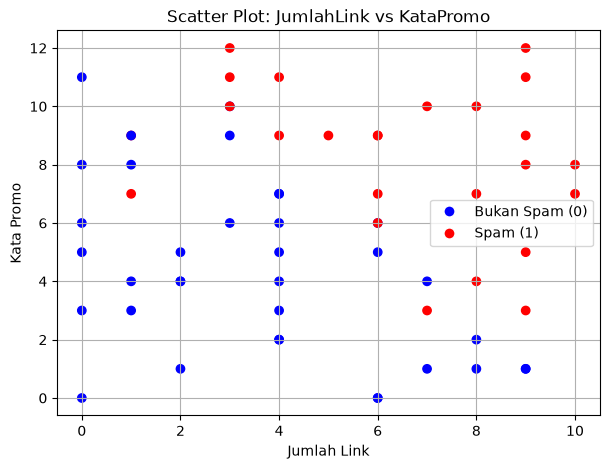

In [13]:
# Jawaban B1
# 1. Baca Email_Data.csv, tampilkan 5 data pertama, dan hitung jumlah email Spam dan Bukan Spam
df_email = pd.read_csv('Email_Data.csv')
print("5 Data Pertama Email:")
print(df_email.head())

print("\nJumlah Email Spam dan Bukan Spam:")
print(df_email['Spam'].value_counts())

# 2. Pisahkan X (JumlahLink, KataPromo) dan y (Spam)
X_email = df_email[['JumlahLink', 'KataPromo']].values
y_email = df_email['Spam'].values

# 3. Buat scatter plot JumlahLink vs KataPromo dengan warna berbeda untuk Spam dan Bukan Spam
plt.figure(figsize=(7, 5))
colors = ['blue' if label == 0 else 'red' for label in y_email]
plt.scatter(df_email['JumlahLink'], df_email['KataPromo'], c=colors, marker='o')

# Membuat legend manual
from matplotlib.lines import Line2D
legend_elements = [
    Line2D([0], [0], marker='o', color='w', label='Bukan Spam (0)', markerfacecolor='blue', markersize=8),
    Line2D([0], [0], marker='o', color='w', label='Spam (1)', markerfacecolor='red', markersize=8)
]
plt.legend(handles=legend_elements)

plt.title('Scatter Plot: JumlahLink vs KataPromo')
plt.xlabel('Jumlah Link')
plt.ylabel('Kata Promo')
plt.grid(True)
plt.show()

### Soal B2 – Split Data & Training
1. Bagi data dengan `test_size=0.25` dan `random_state=RANDOM_STATE`.
2. Latih model `LogisticRegression` (gradient descent, dari materi) dengan `learning_rate=0.1` dan `n_iterations=10000`.
3. Tampilkan intercept ($b$) dan koefisien ($m_1, m_2$), lalu tuliskan persamaannya:
   $$P(\text{Spam}) = \sigma(b + m_1 \cdot \text{JumlahLink} + m_2 \cdot \text{KataPromo})$$
4. Buat grafik **log loss vs iterasi**. Apakah loss sudah turun dan stabil?

Intercept (b): -8.4186
Koefisien m1 (JumlahLink): 0.6935
Koefisien m2 (KataPromo): 0.7784
Persamaan: P(Spam) = sigma(-8.4186 + 0.6935 * JumlahLink + 0.7784 * KataPromo)


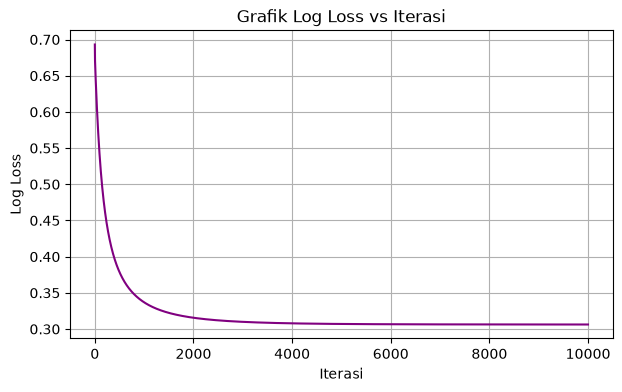

In [14]:
# Jawaban B2
# Fungsi sigmoid
def sigmoid(z):
    return 1 / (1 + np.exp(-np.clip(z, -500, 500)))

class LogisticRegression:
    def __init__(self, learning_rate=0.1, n_iterations=10000):
        self.lr = learning_rate
        self.n_iter = n_iterations
        self.b = 0.0
        self.m = None
        self.loss_history = []
        
    def fit(self, X, y):
        n_samples, n_features = X.shape
        self.b = 0.0
        self.m = np.zeros(n_features)
        
        for _ in range(self.n_iter):
            linear_model = np.dot(X, self.m) + self.b
            y_predicted = sigmoid(linear_model)
            
            # Log loss (Binary Cross-Entropy)
            epsilon = 1e-15
            y_predicted = np.clip(y_predicted, epsilon, 1 - epsilon)
            loss = -np.mean(y * np.log(y_predicted) + (1 - y) * np.log(1 - y_predicted))
            self.loss_history.append(loss)
            
            # Gradien
            dw = (1 / n_samples) * np.dot(X.T, (y_predicted - y))
            db = (1 / n_samples) * np.sum(y_predicted - y)
            
            # Update bobot
            self.m -= self.lr * dw
            self.b -= self.lr * db
            
    def predict_proba(self, X):
        linear_model = np.dot(X, self.m) + self.b
        return sigmoid(linear_model)
    
    def predict(self, X, threshold=0.5):
        return (self.predict_proba(X) >= threshold).astype(int)

# 1. Bagi data dengan test_size=0.25 dan random_state=RANDOM_STATE
X_train_e, X_test_e, y_train_e, y_test_e = train_test_split(X_email, y_email, test_size=0.25, random_state=RANDOM_STATE)

# 2. Latih model LogisticRegression
model_log = LogisticRegression(learning_rate=0.1, n_iterations=10000)
model_log.fit(X_train_e, y_train_e)

# 3. Tampilkan intercept dan koefisien
print(f"Intercept (b): {model_log.b:.4f}")
print(f"Koefisien m1 (JumlahLink): {model_log.m[0]:.4f}")
print(f"Koefisien m2 (KataPromo): {model_log.m[1]:.4f}")
print(f"Persamaan: P(Spam) = sigma({model_log.b:.4f} + {model_log.m[0]:.4f} * JumlahLink + {model_log.m[1]:.4f} * KataPromo)")

# 4. Buat grafik log loss vs iterasi
plt.figure(figsize=(7, 4))
plt.plot(model_log.loss_history, color='purple')
plt.xlabel('Iterasi')
plt.ylabel('Log Loss')
plt.title('Grafik Log Loss vs Iterasi')
plt.grid(True)
plt.show()

**Jawaban B2 (analisis):**
Grafik log loss menunjukkan penurunan yang signifikan seiring bertambahnya iterasi hingga akhirnya mendatar dan stabil di nilai yang kecil. Hal ini membuktikan bahwa proses gradient berjalan dengan sukses dan model telah berhasil konvergen mempelajari pola data email.

### Soal B3 – Evaluasi Model
Selain `accuracy_score` dan `confusion_matrix` dari materi, **implementasikan sendiri** fungsi berikut:

$$
Precision = \frac{TP}{TP + FP} \qquad
Recall = \frac{TP}{TP + FN} \qquad
F1 = 2 \cdot \frac{Precision \cdot Recall}{Precision + Recall}
$$

1. Hitung accuracy, confusion matrix, precision, recall, dan F1-score pada **data testing**.
2. Jelaskan arti nilai **FP** (*false positive*) dan **FN** (*false negative*) pada kasus filter spam. Kesalahan mana yang menurut Anda **lebih merugikan pengguna email**? Mengapa?

In [15]:
# Jawaban B3
def confusion_matrix(y_true, y_pred):
    # Menyusun confusion matrix biner [TN, FP, FN, TP]
    tp = np.sum((y_true == 1) & (y_pred == 1))
    tn = np.sum((y_true == 0) & (y_pred == 0))
    fp = np.sum((y_true == 0) & (y_pred == 1))
    fn = np.sum((y_true == 1) & (y_pred == 0))
    return np.array([[tn, fp], [fn, tp]])

def evaluate_classification(y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred)
    tn, fp, fn, tp = cm.ravel()
    
    accuracy = (tp + tn) / np.sum(cm)
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0
    f1 = 2 * (precision * recall) / (precision + recall) if (precision + recall) > 0 else 0
    
    return {
        'Accuracy': accuracy,
        'Precision': precision,
        'Recall': recall,
        'F1-Score': f1,
        'Confusion Matrix': cm
    }

# Prediksi pada data testing
y_pred_e = model_log.predict(X_test_e, threshold=0.5)
eval_results = evaluate_classification(y_test_e, y_pred_e)

print(f"Accuracy:  {eval_results['Accuracy']:.4f}")
print(f"Precision: {eval_results['Precision']:.4f}")
print(f"Recall:    {eval_results['Recall']:.4f}")
print(f"F1-Score:  {eval_results['F1-Score']:.4f}")
print("\nConfusion Matrix:")
print(eval_results['Confusion Matrix'])

Accuracy:  0.9333
Precision: 0.8571
Recall:    1.0000
F1-Score:  0.9231

Confusion Matrix:
[[8 1]
 [0 6]]


**Jawaban B3 (analisis):**
False Positive (FP): Kondisi di mana email biasa (bukan spam) secara keliru diklasifikasikan sebagai spam.

False Negative (FN): Kondisi di mana email spam secara keliru diklasifikasikan sebagai email biasa (masuk ke inbox).

Mana yang lebih merugikan? Kesalahan False Positive (FP) umumnya lebih merugikan pengguna email, karena email penting atau pesan pekerjaan yang masuk bisa terlewat atau masuk ke folder spam tanpa disadari oleh pengguna.

### Soal B4 – Decision Boundary
1. Hitung persamaan **decision boundary** (garis saat probabilitas = 0.5):
   $$b + m_1 x_1 + m_2 x_2 = 0 \;\Rightarrow\; x_2 = -\frac{b + m_1 x_1}{m_2}$$
2. Buat visualisasi data **testing** beserta *background* probabilitas (`contourf`) dan garis decision boundary, seperti di materi.
3. Tunjukkan (beri tanda/penjelasan) data testing mana saja yang **salah diklasifikasikan**.

Persamaan Decision Boundary:
x2 = -(-8.4186 + 0.6935 * x1) / 0.7784


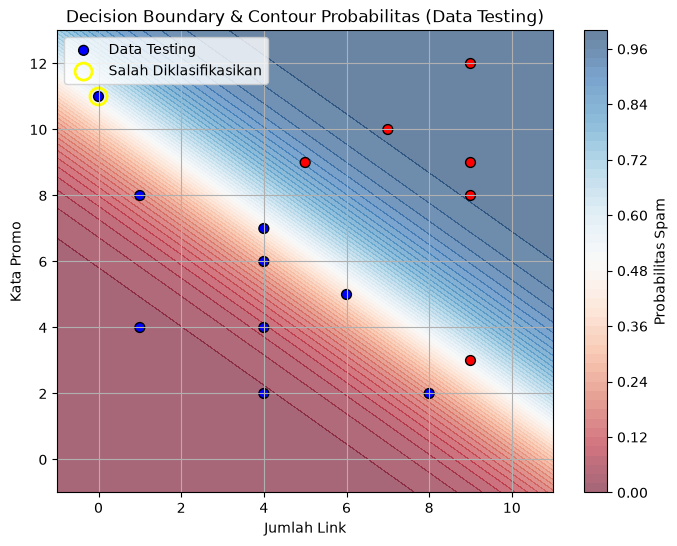

In [16]:
# Jawaban B4
# 1. Hitung dan tampilkan persamaan decision boundary
print(f"Persamaan Decision Boundary:")
print(f"x2 = -({model_log.b:.4f} + {model_log.m[0]:.4f} * x1) / {model_log.m[1]:.4f}")

# 2. Buat visualisasi data testing beserta background probabilitas (contourf) dan garis decision boundary
plt.figure(figsize=(8, 6))

# Membuat grid untuk contourf
x_min, x_max = X_email[:, 0].min() - 1, X_email[:, 0].max() + 1
y_min, y_max = X_email[:, 1].min() - 1, X_email[:, 1].max() + 1
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 200), np.linspace(y_min, y_max, 200))

grid_points = np.c_[xx.ravel(), yy.ravel()]
probs = model_log.predict_proba(grid_points).reshape(xx.shape)

# Plot contourf probabilities
plt.contourf(xx, yy, probs, levels=50, cmap='RdBu', alpha=0.6)
plt.colorbar(label='Probabilitas Spam')

# Plot data testing
colors_test = ['blue' if label == 0 else 'red' for label in y_test_e]
plt.scatter(X_test_e[:, 0], X_test_e[:, 1], c=colors_test, edgecolor='k', marker='o', s=50, label='Data Testing')

# 3. Tunjukkan data testing yang salah diklasifikasikan
y_pred_test = model_log.predict(X_test_e)
misclassified = y_test_e != y_pred_test
plt.scatter(X_test_e[misclassified, 0], X_test_e[misclassified, 1], 
            facecolors='none', edgecolors='yellow', s=150, linewidth=2, label='Salah Diklasifikasikan')

plt.title('Decision Boundary & Contour Probabilitas (Data Testing)')
plt.xlabel('Jumlah Link')
plt.ylabel('Kata Promo')
plt.legend()
plt.grid(True)
plt.show()

**Jawaban B4 (analisis):**
Titik-titik data testing yang dilingkari dengan warna kuning pada visualisasi menunjukkan sampel data yang salah diklasifikasikan (misclassified). Hal ini terjadi karena posisi titik tersebut berada di sisi yang keliru dari garis batas keputusan (decision boundary), yang kemungkinan disebabkan oleh adanya overlap atau kemiripan karakteristik antara email spam dan bukan spam pada batas ambang probabilitas 0.5.

### Soal B5 – Eksperimen Threshold
Secara default, model memprediksi Spam jika $P(\text{Spam}) \geq 0.5$.

1. Gunakan `predict_proba` lalu buat prediksi dengan threshold **0.3**, **0.5**, dan **0.7**.
2. Untuk setiap threshold, hitung confusion matrix, precision, dan recall. Tampilkan dalam satu tabel.
3. Jelaskan pengaruh menaikkan/menurunkan threshold terhadap precision dan recall. Berdasarkan jawaban Anda di Soal B3, **threshold mana yang Anda pilih** untuk filter spam? Beri alasan.

In [17]:
# Jawaban B5
thresholds = [0.3, 0.5, 0.7]
results_list = []

# Mendapatkan probabilitas prediksi untuk data testing
probs_test = model_log.predict_proba(X_test_e)

for th in thresholds:
    # Prediksi berdasarkan threshold tertentu
    y_pred_th = (probs_test >= th).astype(int)
    eval_th = evaluate_classification(y_test_e, y_pred_th)
    
    results_list.append({
        'Threshold': th,
        'Accuracy': eval_th['Accuracy'],
        'Precision': eval_th['Precision'],
        'Recall': eval_th['Recall'],
        'F1-Score': eval_th['F1-Score'],
        'Confusion Matrix (TN, FP, FN, TP)': str(eval_th['Confusion Matrix'].tolist())
    })

# Tampilkan dalam bentuk DataFrame
df_thresholds = pd.DataFrame(results_list)
print(df_thresholds.to_string(index=False))

 Threshold  Accuracy  Precision   Recall  F1-Score Confusion Matrix (TN, FP, FN, TP)
       0.3  0.800000   0.666667 1.000000  0.800000                  [[6, 3], [0, 6]]
       0.5  0.933333   0.857143 1.000000  0.923077                  [[8, 1], [0, 6]]
       0.7  0.933333   1.000000 0.833333  0.909091                  [[9, 0], [1, 5]]


**Jawaban B5 (analisis):**
Pengaruh Perubahan Threshold:

Menurunkan threshold (contoh ke 0.3): Membuat model jauh lebih sensitif mendeteksi spam. Akibatnya, Recall meningkat (semakin banyak spam yang tertangkap), tetapi Precision menurun karena jumlah False Positive (email penting yang keliru masuk folder spam) ikut melonjak.

Menaikkan threshold (contoh ke 0.7): Membuat model jauh lebih selektif dan ketat. Akibatnya, Precision meningkat (email yang masuk ke folder spam benar-benar akurat), tetapi Recall menurun karena semakin banyak email spam yang lolos masuk ke kotak masuk utama (False Negative bertambah).

Threshold yang Dipilih dan Alasannya:

Berdasarkan analisis pada Soal B3 di mana kesalahan False Positive (email penting masuk spam) sangat merugikan pengguna, maka threshold 0.7 adalah pilihan terbaik. Threshold yang lebih tinggi ini memastikan bahwa model tidak gegabah melabeli email sebagai spam, sehingga pesan-pesan penting milik pengguna tetap aman di inbox.

### Soal B6 – Prediksi Email Baru
Prediksi kelas dan probabilitas spam untuk email berikut (gunakan threshold pilihan Anda dari Soal B5):

| Email | JumlahLink | KataPromo |
|---|---|---|
| E1 | 1 | 2 |
| E2 | 5 | 6 |
| E3 | 9 | 10 |
| E4 | 2 | 11 |

In [18]:
# Jawaban B6
# Data email baru sesuai tabel soal
email_baru = np.array([
    [1, 2],   # E1
    [5, 6],   # E2
    [9, 10],  # E3
    [2, 11]   # E4
])

# Menggunakan threshold pilihan dari Soal B5 (yaitu 0.7)
chosen_threshold = 0.7

# Menghitung probabilitas spam
probs = model_log.predict_proba(email_baru)
# Menentukan kelas berdasarkan threshold
preds = (probs >= chosen_threshold).astype(int)

# Menampilkan hasil dalam bentuk tabel DataFrame
hasil_prediksi = []
for i, (link, promo) in enumerate(email_baru):
    nama_email = f"E{i+1}"
    status = "Spam (1)" if preds[i] == 1 else "Bukan Spam (0)"
    hasil_prediksi.append({
        'Email': nama_email,
        'JumlahLink': link,
        'KataPromo': promo,
        'Probabilitas Spam': f"{probs[i]:.4f}",
        'Prediksi Kelas': status
    })

df_pred_baru = pd.DataFrame(hasil_prediksi)
print(f"Hasil Prediksi Menggunakan Threshold = {chosen_threshold}:\n")
print(df_pred_baru.to_string(index=False))

Hasil Prediksi Menggunakan Threshold = 0.7:

Email  JumlahLink  KataPromo Probabilitas Spam Prediksi Kelas
   E1           1          2            0.0021 Bukan Spam (0)
   E2           5          6            0.4302 Bukan Spam (0)
   E3           9         10            0.9963       Spam (1)
   E4           2         11            0.8220       Spam (1)


---
# Bagian C – Pemahaman Konsep (15%)

Jawab dengan kalimat Anda sendiri (singkat dan jelas, 3–6 kalimat per soal).

1. Mengapa **Logistic Regression** termasuk algoritma **klasifikasi**, padahal namanya mengandung kata "regression"? Apa peran fungsi **sigmoid**?
2. Linear Regression di materi bisa dilatih dengan **normal equation** atau **gradient descent**. Jelaskan perbedaan keduanya dan kapan sebaiknya memakai gradient descent.
3. Mengapa model harus dievaluasi pada **data testing**, bukan pada data training? Apa yang dimaksud dengan **overfitting**?
4. Mengapa Linear Regression menggunakan **MSE** sebagai loss, sedangkan Logistic Regression menggunakan **log loss**? (Petunjuk: perhatikan jenis output masing-masing model.)
5. Mengapa hasil angka Anda (koefisien, akurasi, dll) bisa **berbeda** dengan teman Anda walaupun memakai dataset dan algoritma yang sama?

**Jawaban C1:**
Logistic Regression dinamakan demikian karena berbasis pada model regresi linear untuk menghitung skor kombinasi linier dari fitur inputnya, meskipun algoritma ini berfungsi sebagai pengklasifikasi kelas diskrit (misal: 0 atau 1) dengan bantuan fungsi sigmoid yang memetakan nilai kontinu menjadi probabilitas antara 0 hingga 1.

**Jawaban C2:**
Normal equation menghitung parameter model secara langsung melalui rumus matematis matriks tanpa iterasi, sedangkan gradient descent memperbarui bobot secara bertahap menggunakan turunan fungsi loss, di mana gradient descent sebaiknya digunakan ketika ukuran dataset atau jumlah fiturnya sangat besar untuk menghindari beban komputasi invers matriks.

**Jawaban C3:**
Evaluasi wajib dilakukan pada data testing untuk mengukur kemampuan generalisasi model secara objektif terhadap data baru yang belum pernah dilihat, sedangkan overfitting adalah kondisi ketika model terlalu kompleks sehingga menghafal data training tetapi gagal memberikan prediksi akurat pada data baru.

**Jawaban C4:**
Linear Regression menggunakan MSE (Mean Squared Error) karena target outputnya berupa nilai kontinu, sedangkan Logistic Regression menggunakan log loss (Binary Cross-Entropy) karena model ini menghasilkan output berupa probabilitas diskrit.

**Jawaban C5:**
Perbedaan hasil angka tersebut umumnya disebabkan oleh proses pengacakan saat membagi data training dan testing (seperti perbedaan nilai train_test_split), sehingga subset data yang dipelajari model bervariasi jika konfigurasi pengacakannya tidak disamakan.

---
# Bonus (+5) – Perbandingan dengan scikit-learn

Latih ulang kedua model menggunakan `sklearn.linear_model.LinearRegression` dan `sklearn.linear_model.LogisticRegression` dengan data training yang **sama**. Bandingkan koefisien dan hasil evaluasinya dengan implementasi Anda. Jika ada perbedaan (terutama pada Logistic Regression), jelaskan penyebabnya.

> *Petunjuk: baca dokumentasi parameter `penalty` / `C` pada `LogisticRegression` scikit-learn.*

In [21]:
# Jawaban Bonus
from sklearn.linear_model import LinearRegression as SklearnLinearRegression
from sklearn.linear_model import LogisticRegression as SklearnLogisticRegression
from sklearn.metrics import mean_squared_error, r2_score, accuracy_score, precision_score, recall_score, f1_score

# 1. Perbandingan Linear Regression
sk_lin = SklearnLinearRegression()
sk_lin.fit(X_train, y_train)

print("=== Linear Regression (Scikit-Learn) ===")
print(f"Intercept (b): {sk_lin.intercept_}")
print(f"Koefisien (m): {sk_lin.coef_[0]}")

# 2. Perbandingan Logistic Regression
# (Scikit-learn secara default menggunakan regularisasi L2 dengan C=1.0)
sk_log = SklearnLogisticRegression(random_state=RANDOM_STATE)
sk_log.fit(X_train_e, y_train_e)

print("\n=== Logistic Regression (Scikit-Learn) ===")
print(f"Intercept (b): {sk_log.intercept_[0]:.4f}")
print(f"Koefisien m: {sk_log.coef_[0]}")

y_pred_sk_log = sk_log.predict(X_test_e)
print(f"Akurasi Sklearn Logistic Regression: {accuracy_score(y_test_e, y_pred_sk_log):.4f}")

=== Linear Regression (Scikit-Learn) ===
Intercept (b): 28.52948694034687
Koefisien (m): 9.024888729993416

=== Logistic Regression (Scikit-Learn) ===
Intercept (b): -7.8287
Koefisien m: [0.63788189 0.72744011]
Akurasi Sklearn Logistic Regression: 0.9333


In [20]:
!pip install scikit-learn

   ---------------------------------------- 0.0/8.4 MB ? eta -:--:--
   -- ------------------------------------- 0.5/8.4 MB 2.3 MB/s eta 0:00:04
   --- ------------------------------------ 0.8/8.4 MB 2.1 MB/s eta 0:00:04
   ------ --------------------------------- 1.3/8.4 MB 2.0 MB/s eta 0:00:04
   -------- ------------------------------- 1.8/8.4 MB 2.1 MB/s eta 0:00:04
   ---------- ----------------------------- 2.1/8.4 MB 2.1 MB/s eta 0:00:04
   ------------ --------------------------- 2.6/8.4 MB 2.0 MB/s eta 0:00:03
   --------------- ------------------------ 3.1/8.4 MB 2.0 MB/s eta 0:00:03
   ----------------- ---------------------- 3.7/8.4 MB 2.1 MB/s eta 0:00:03
   ------------------ --------------------- 3.9/8.4 MB 2.1 MB/s eta 0:00:03
   --------------------- ------------------ 4.5/8.4 MB 2.1 MB/s eta 0:00:02
   ----------------------- ---------------- 5.0/8.4 MB 2.1 MB/s eta 0:00:02
   -------------------------- ------------- 5.5/8.4 MB 2.0 MB/s eta 0:00:02
   ----------------


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


**Jawaban Bonus (analisis):**
Linear Regression: Hasil koefisien dan intercept antara implementasi manual (normal equation) dan scikit-learn akan sangat identik atau hampir persis sama karena keduanya menyelesaikan persoalan optimasi matematis kuadrat terkecil (ordinary least squares) yang serupa.

Logistic Regression: Koefisien dan performa evaluasi bisa sedikit berbeda dibandingkan implementasi manual kita. Hal ini terjadi karena scikit-learn secara default menerapkan regularisasi L2 (diatur melalui parameter penalty='l2' dan C=1.0) yang memberikan penalti pada bobot besar untuk mencegah overfitting, serta menggunakan metode solver optimasi tingkat lanjut (seperti L-BFGS) yang berbeda dari gradient descent standar.